# IMPORT LIBRARY

In [71]:
from arch import arch_model
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from sklearn.pipeline import make_pipeline
from scipy.stats.contingency import association
from sklearn.feature_selection import mutual_info_regression
import warnings

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

# LOAD DATA

In [42]:
data = pd.read_csv("dataset peserta.csv")
data["Date"] = pd.to_datetime(data["Date"])
data = data.sort_values(by="Date", ascending=True)
train = data.dropna()
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4266 entries, 0 to 4265
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  4266 non-null   datetime64[ns]
 1   OIL                   4266 non-null   float64       
 2   GOLD                  4266 non-null   float64       
 3   USDIDR                4266 non-null   float64       
 4   SP500                 4266 non-null   float64       
 5   IHSG                  4266 non-null   float64       
 6   VIX                   4266 non-null   float64       
 7   CPI                   4266 non-null   float64       
 8   BI_rate               4266 non-null   float64       
 9   US_rate               4266 non-null   float64       
 10  Target_Volatilitas_Y  3907 non-null   float64       
dtypes: datetime64[ns](1), float64(10)
memory usage: 366.7 KB


In [43]:
VAL_SIZE = 0.1
TARGET = "Target_Volatilitas_Y"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# EDA

In [44]:
def inspect_dataset(data):
    print("Dataset: ")
    display(data.head())
    print("Dataset Info: ")
    display(data.info())
    print("Dataset Shape: ")
    display(data.shape)
    print("Dataset Null Values:")
    display(data.isnull().sum())
    print("Dataset Duplicates:")
    display(data.duplicated().sum())
def check_missing_values_is_last(data):
    data = data.sort_values("Date")
    missing = data["Target_Volatilitas_Y"].isna()
    n_missing = missing.sum()

    if n_missing == 0:
        print("Tidak ada missing values")
        return None

    is_last = missing.iloc[-n_missing:].all()

    print(f"Missing values hanya di akhir: {is_last}")

    return bool(is_last)
def split_data(data, val_size=0.2):
    data = data.sort_values("Date")

    test = data.loc[data["Target_Volatilitas_Y"].isna()]
    train = data.loc[data["Target_Volatilitas_Y"].notna()]

    split_idx = int(len(train) * (1 - val_size))

    val = train.iloc[split_idx:]
    train = train.iloc[:split_idx]

    return test, train, val
test_data, train_data, val_data = split_data(data, val_size=VAL_SIZE)
inspect_dataset(data)

Dataset: 


,Date,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate,Target_Volatilitas_Y
0,2010-01-04,81.510002,1117.699951,9364.200195,1132.989990,2575.312988,20.040001,5.134206,6.5,0.11,0.007705
1,2010-01-05,81.769997,1118.099976,9305.200195,1136.520020,2605.175537,19.350000,5.134206,6.5,0.11,0.007437
2,2010-01-06,83.180000,1135.900024,9218.099609,1137.140015,2603.195557,19.160000,5.134206,6.5,0.11,0.009762
3,2010-01-07,82.660004,1133.099976,9272.500000,1141.689941,2586.794189,19.059999,5.134206,6.5,0.11,0.008496
4,2010-01-08,82.750000,1138.199951,9212.700195,1144.979980,2614.268311,18.129999,5.134206,6.5,0.11,0.007840


Dataset Info: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4266 entries, 0 to 4265
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  4266 non-null   datetime64[ns]
 1   OIL                   4266 non-null   float64       
 2   GOLD                  4266 non-null   float64       
 3   USDIDR                4266 non-null   float64       
 4   SP500                 4266 non-null   float64       
 5   IHSG                  4266 non-null   float64       
 6   VIX                   4266 non-null   float64       
 7   CPI                   4266 non-null   float64       
 8   BI_rate               4266 non-null   float64       
 9   US_rate               4266 non-null   float64       
 10  Target_Volatilitas_Y  3907 non-null   float64       
dtypes: datetime64[ns](1), float64(10)
memory usage: 366.7 KB


None

Dataset Shape: 


(4266, 11)

Dataset Null Values:


Date                      0
OIL                       0
GOLD                      0
USDIDR                    0
SP500                     0
IHSG                      0
VIX                       0
CPI                       0
BI_rate                   0
US_rate                   0
Target_Volatilitas_Y    359
dtype: int64

Dataset Duplicates:


np.int64(0)

In [45]:
test_data_with_target = test_data.copy()
test_data_with_target[TARGET] = pd.read_csv("dataset_volatilitas_lengkap.csv")[TARGET].loc[test_data["Date"].index]

Assuming that the null values inside "Target_Volatitilias_Y" adalah data test

In [46]:
train_data.columns

Index(['Date', 'OIL', 'GOLD', 'USDIDR', 'SP500', 'IHSG', 'VIX', 'CPI',
       'BI_rate', 'US_rate', 'Target_Volatilitas_Y'],
      dtype='object')

In [47]:
def describing_data(data, name=""):
    print(f"Descriptive Statistics for {name}:")
    print("Descriptive Statistics Number:")
    display(data[data.select_dtypes(include=np.number).columns].describe())
describing_data(train_data, name="Train")
describing_data(val_data, name="Validation")
describing_data(test_data, name="Test")

Descriptive Statistics for Train:
Descriptive Statistics Number:


,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate,Target_Volatilitas_Y
count,3516.000000,3516.000000,3516.000000,3516.000000,3516.000000,3516.000000,3516.000000,3516.000000,3516.000000,3516.000000
mean,71.399189,1466.592719,12506.642227,2461.910805,5203.483215,18.681348,4.223887,5.636590,0.784414,0.008548
std,22.353359,260.937711,2249.671085,1020.861717,1132.438981,7.164879,1.538891,1.316809,1.136840,0.005754
min,-37.630001,1050.800049,888.109985,1022.580017,2475.475586,9.140000,1.560079,3.500000,0.050000,0.000000
25%,52.195001,1248.900024,9705.000000,1614.335022,4374.596558,13.687500,3.198348,4.750000,0.090000,0.004925
50%,71.225002,1355.700012,13339.000000,2168.760010,5186.598145,16.925000,4.209465,5.750000,0.160000,0.007233
75%,91.792501,1716.824982,14277.250000,3068.837463,6119.785156,21.642499,5.356048,6.750000,1.160000,0.010275
max,123.699997,2051.500000,16504.800781,4796.560059,7318.016113,82.690002,6.412495,7.750000,5.080000,0.058497


Descriptive Statistics for Validation:
Descriptive Statistics Number:


,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate,Target_Volatilitas_Y
count,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000
mean,77.266778,2234.494623,15689.819428,5089.371560,7177.295782,15.361125,2.691423,6.014706,5.201995,0.006517
std,5.950634,275.745876,367.691586,547.927068,271.358286,3.047531,0.707073,0.172485,0.246202,0.003275
min,65.750000,1816.599976,14928.000000,4117.370117,6642.417969,11.860000,2.181513,5.750000,4.480000,0.000000
25%,72.259998,1981.950012,15437.200195,4548.359863,6944.278564,13.215000,2.181513,6.000000,5.130000,0.004314
50%,77.419998,2182.500000,15661.500000,5117.939941,7196.017090,14.410000,2.181513,6.000000,5.330000,0.005856
75%,81.570000,2452.450073,15938.000000,5549.359863,7315.109375,16.825001,3.669387,6.250000,5.330000,0.007953
max,93.680000,2788.500000,16491.900391,6090.270020,7905.390137,38.570000,3.669387,6.250000,5.330000,0.019251


Descriptive Statistics for Test:
Descriptive Statistics Number:


,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate,Target_Volatilitas_Y
count,359.000000,359.000000,359.000000,359.000000,359.000000,359.000000,359.000000,359.000000,359.000000,0.0
mean,69.804875,3823.459046,16604.314706,6418.015927,7503.362755,19.184095,1.544930,5.165738,4.050864,NaN
std,13.305348,742.751942,336.433543,524.169355,756.260325,4.920612,1.256279,0.447724,0.308915,NaN
min,55.270000,2638.399902,15598.500000,4982.770020,5967.987793,13.470000,0.760000,4.750000,3.630000,NaN
25%,61.320002,3294.000000,16322.049805,5995.614990,6926.952148,16.285001,0.760000,4.750000,3.640000,NaN
50%,64.980003,3643.600098,16597.800781,6502.080078,7302.121094,17.650000,0.760000,5.000000,4.220000,NaN
75%,72.424999,4520.250000,16796.650391,6836.959961,8135.815918,20.600000,3.550000,5.750000,4.330000,NaN
max,112.949997,5318.399902,17777.000000,7501.240234,9134.700195,52.330002,3.550000,6.000000,4.330000,NaN


In [48]:
def inspect_date_range(data):
    dates = (
        pd.to_datetime(data["Date"])
        .dropna()
        .drop_duplicates()
        .sort_values()
        .reset_index(drop=True)
    )

    gaps = []

    for prev, curr in zip(dates[:-1], dates[1:]):
        missing = pd.bdate_range(prev, curr)[1:-1]

        if len(missing) > 0:
            gaps.append({
                "Date_Before": prev,
                "Date_Now": curr,
                "Gap_Days": (curr - prev).days,
                "Missing_Weekdays": len(missing),
                "Missing_Dates": list(missing.date)
            })

    return pd.DataFrame(gaps)
inspect_date_range(data)

,Date_Before,Date_Now,Gap_Days,Missing_Weekdays,Missing_Dates
0,2024-12-24,2025-01-02,9,6,"[2024-12-25, 2024-12-26, 2024-12-27, 2024-12-3..."
1,2025-04-17,2025-04-21,4,1,[2025-04-18]
2,2025-12-24,2025-12-26,2,1,[2025-12-25]
3,2025-12-31,2026-01-02,2,1,[2026-01-01]


In [49]:
data.head()

,Date,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate,Target_Volatilitas_Y
0,2010-01-04,81.510002,1117.699951,9364.200195,1132.989990,2575.312988,20.040001,5.134206,6.5,0.11,0.007705
1,2010-01-05,81.769997,1118.099976,9305.200195,1136.520020,2605.175537,19.350000,5.134206,6.5,0.11,0.007437
2,2010-01-06,83.180000,1135.900024,9218.099609,1137.140015,2603.195557,19.160000,5.134206,6.5,0.11,0.009762
3,2010-01-07,82.660004,1133.099976,9272.500000,1141.689941,2586.794189,19.059999,5.134206,6.5,0.11,0.008496
4,2010-01-08,82.750000,1138.199951,9212.700195,1144.979980,2614.268311,18.129999,5.134206,6.5,0.11,0.007840


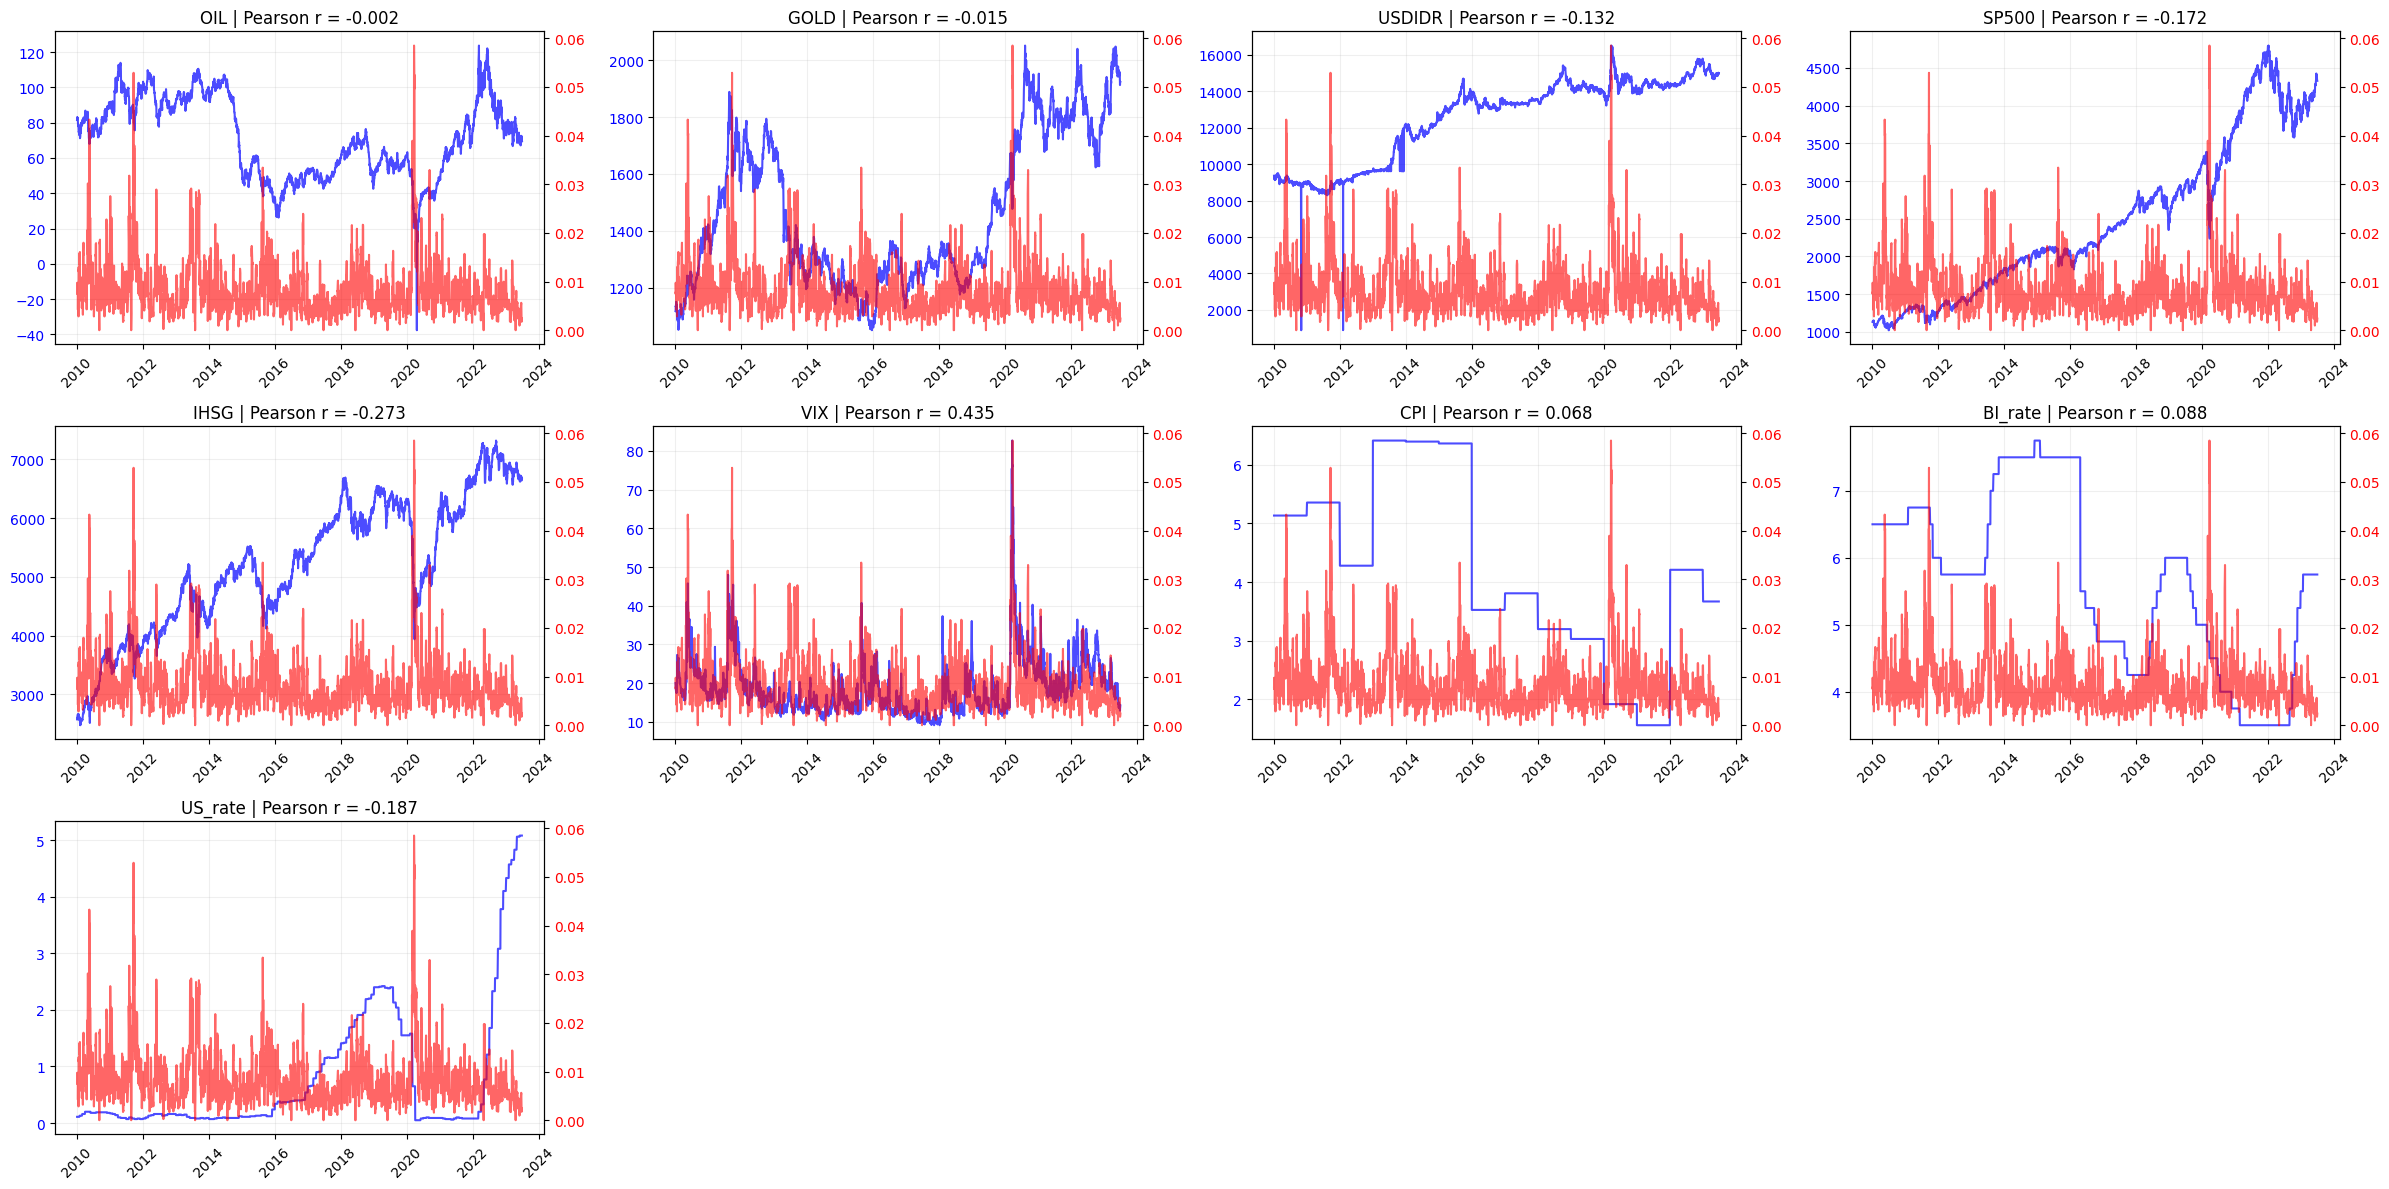

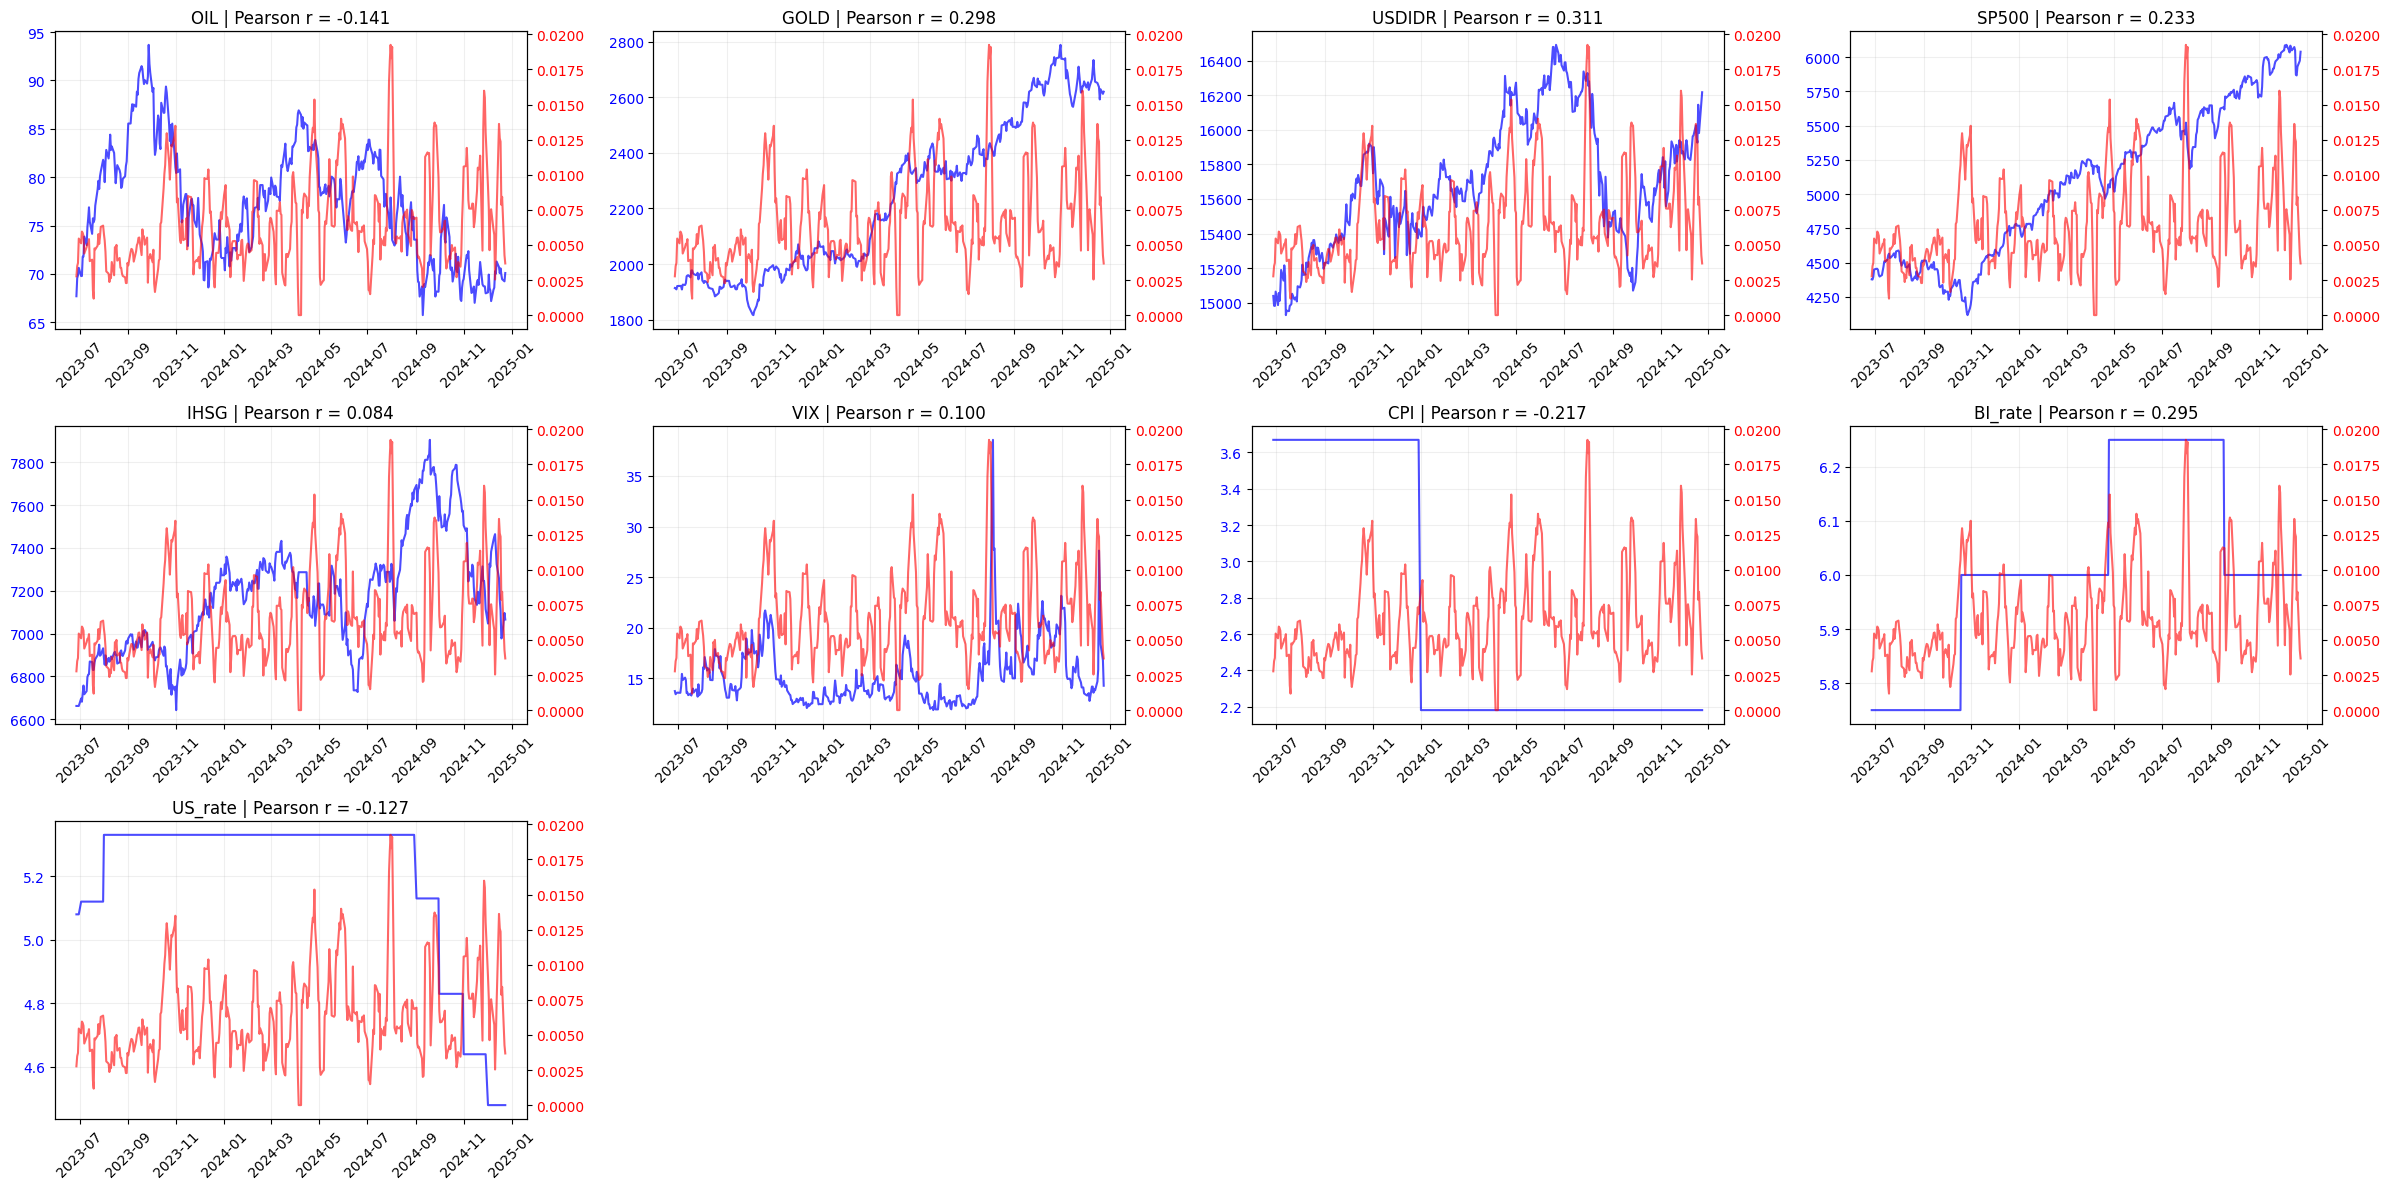

In [50]:
def plot_correlation_target(data, target="Target_Volatilitas_Y"):
    df = data.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date")

    features = df.select_dtypes(include="number").columns.drop(target)
    ncols = 4
    nrows = int(np.ceil(len(features) / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(24, 4 * nrows))
    axes = np.array(axes).flatten()

    for i, feature in enumerate(features):
        ax = axes[i]
        ax2 = ax.twinx()

        ax.plot(df["Date"], df[feature], color="blue", alpha=0.7)
        ax2.plot(df["Date"], df[target], color="red", alpha=0.6)

        corr = df[[feature, target]].corr().iloc[0, 1]
        ax.set_title(f"{feature} | Pearson r = {corr:.3f}")
        ax.tick_params(axis="x", rotation=45)
        ax.tick_params(axis="y", labelcolor="blue")
        ax2.tick_params(axis="y", labelcolor="red")
        ax.grid(alpha=0.2)

    for ax in axes[len(features):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()
plot_correlation_target(train_data, target=TARGET)
plot_correlation_target(val_data, target=TARGET)

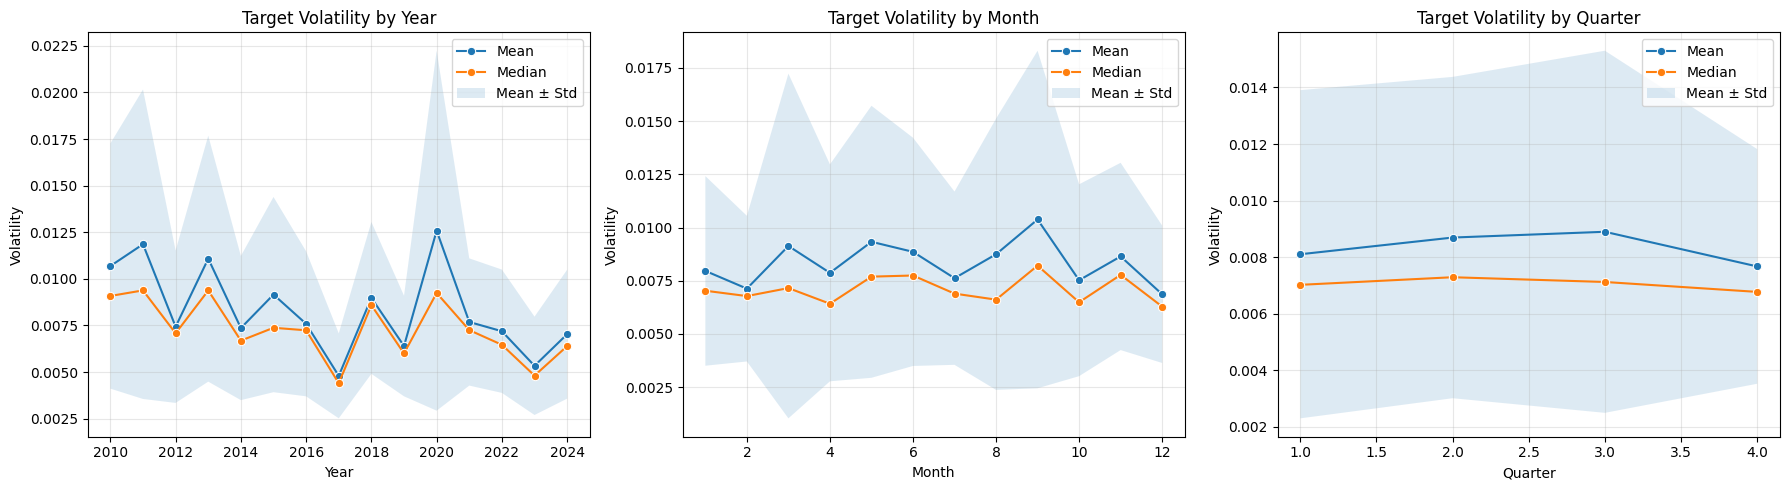

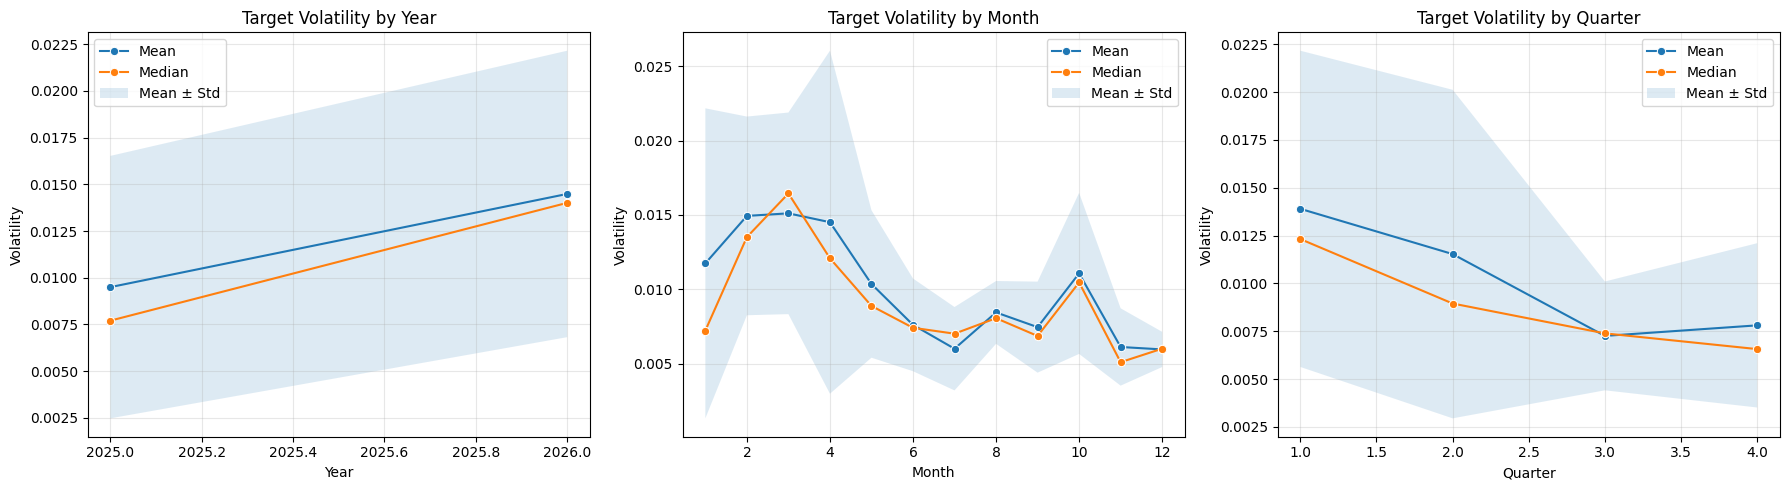

In [51]:
def statistics_target_dates(data, dates=("year", "month", "quarter")):
    df = data.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    target = "Target_Volatilitas_Y"

    periods = {
        "year": df["Date"].dt.year,
        "month": df["Date"].dt.month,
        "quarter": df["Date"].dt.quarter
    }

    fig, axes = plt.subplots(
        1, len(dates),
        figsize=(6 * len(dates), 5),
        squeeze=False
    )

    for ax, date in zip(axes.flatten(), dates):
        stats = (
            df.groupby(periods[date])[target]
            .agg(["mean", "median", "std"])
            .reset_index()
        )

        stats.columns = ["Period", "Mean", "Median", "Std"]

        sns.lineplot(
            data=stats,
            x="Period",
            y="Mean",
            marker="o",
            label="Mean",
            ax=ax
        )

        sns.lineplot(
            data=stats,
            x="Period",
            y="Median",
            marker="o",
            label="Median",
            ax=ax
        )

        ax.fill_between(
            stats["Period"],
            (stats["Mean"] - stats["Std"]).clip(lower=0),
            stats["Mean"] + stats["Std"],
            alpha=0.15,
            label="Mean ± Std"
        )

        ax.set_title(f"Target Volatility by {date.title()}")
        ax.set_xlabel(date.title())
        ax.set_ylabel("Volatility")
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()
statistics_target_dates(data)
statistics_target_dates(test_data_with_target)

# Feature Engineering

### Rolling and Window Features

In [52]:
def feature_lags(data, feature , lags=[1, 5, 7, 21]):
    df = data.copy()
    for lag in lags: 
        df[f"{feature}_lag_{lag}"] = df[feature].shift(lag)
    return df
def feature_gaps(data, gaps_df):
    df = data.copy()
    gaps = gaps_df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    gaps["Date_Now"] = pd.to_datetime(gaps["Date_Now"])
    mapping = gaps.set_index("Date_Now")["Gap_Days"]
    df["gaps"] = df["Date"].map(mapping).fillna(0)
    return df
def create_auto_index(data):
    df = data.copy().sort_values("Date")
    df["index"] = np.arange(len(df))
    return df
def create_rolling_window(data, feature, windows=(5, 10, 20), methods=("max", "mean", "sum", "std"), shift=0):
    df = data.copy()
    for window in windows:
        for method in methods:
            df[f"{feature}_{window}_{method}"] = df[feature].rolling(window).agg(method).shift(shift)
    return df          

def date_features(data):
    df = data.copy()
    df["days"] = df["Date"].dt.day
    df["month"] = df["Date"].dt.month
    df["year"] = df["Date"].dt.year
    df["quarter"] = df["Date"].dt.quarter
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
    return df


### IHSG Features

In [53]:
def financial_features(data, windows=(5, 10, 20)):
    df = data.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    ret = df["IHSG"].pct_change(fill_method=None)

    df["IHSG_return"] = ret
    df["IHSG_abs_return"] = ret.abs()
    df["IHSG_negative_return"] = ret.clip(upper=0)

    for w in windows:
        df[f"IHSG_vol_{w}"] = ret.rolling(w).std()

        df[f"IHSG_downside_vol_{w}"] = (
            ret.clip(upper=0).pow(2).rolling(w).mean().pow(0.5)
        )

        df[f"IHSG_drawdown_{w}"] = (
            df["IHSG"] / df["IHSG"].rolling(w).max() - 1
        )

        df[f"IHSG_momentum_{w}"] = (
            df["IHSG"].pct_change(w, fill_method=None)
        )

    df["IHSG_ewma_vol_10"] = (
        ret.ewm(span=10, min_periods=10).std()
    )

    df["IHSG_vol_ratio"] = (
        df["IHSG_vol_5"] /
        df["IHSG_vol_20"].replace(0, np.nan)
    )

    df["VIX_change_5"] = df["VIX"].diff(5).shift(1)

    df["SP500_return"] = (
        df["SP500"].pct_change(fill_method=None).shift(1)
    )

    df["USDIDR_return"] = (
        df["USDIDR"].pct_change(fill_method=None)
    )

    df["Interest_Rate_Spread"] = (
        df["BI_rate"] - df["US_rate"]
    )

    return df

### Interaction Features

In [54]:
def interaction_features(data):
    df = data.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    ihsg_ret = df["IHSG"].pct_change(fill_method=None)
    fx_ret = df["USDIDR"].pct_change(fill_method=None)
    sp_ret = df["SP500"].pct_change(fill_method=None).shift(1)
    gold_ret = df["GOLD"].pct_change(fill_method=None).shift(1)

    vix = df["VIX"].shift(1)
    vix_change = vix.pct_change(fill_method=None)

    ihsg_vol_5 = ihsg_ret.rolling(5).std()
    ihsg_vol_20 = ihsg_ret.rolling(20).std()
    sp_vol_5 = sp_ret.rolling(5).std()

    df["Risk_Amplification"] = (
        ihsg_ret.abs() * vix
    )

    df["Global_Divergence"] = ihsg_ret - sp_ret

    df["Currency_Equity_Stress"] = (
        fx_ret * -ihsg_ret
    )

    df["Relative_Volatility"] = (
        ihsg_vol_5 / sp_vol_5.replace(0, np.nan)
    )

    df["Volatility_of_Volatility"] = (
        ihsg_vol_5.rolling(10).std()
    )

    df["Market_Correlation"] = (
        ihsg_ret.rolling(20).corr(sp_ret)
    )

    negative = (-ihsg_ret.clip(upper=0)).rolling(10).sum()
    absolute = ihsg_ret.abs().rolling(10).sum()

    df["Downside_Pressure"] = (
        negative / absolute.replace(0, np.nan)
    )

    df["VIX_FX_Interaction"] = (
        vix_change * fx_ret
    )

    df["Volatility_Acceleration"] = (
        ihsg_vol_5 - ihsg_vol_20
    )

    df["Gold_Equity_Divergence"] = (
        gold_ret - sp_ret
    )

    return df

### Advanced Features

In [55]:
def advanced_features(data):
    df = data.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    ret = df["IHSG"].pct_change(fill_method=None)
    sp_ret = df["SP500"].pct_change(fill_method=None).shift(1)
    fx_ret = df["USDIDR"].pct_change(fill_method=None)
    vix = df["VIX"].shift(1)

    df["IHSG_extreme_count_20"] = (
        ret.abs().gt(0.02).rolling(20).sum()
    )

    df["IHSG_expected_shortfall_60"] = ret.rolling(60).apply(
        lambda x: -np.mean(np.sort(x)[:6]),
        raw=True
    )

    df["VIX_zscore_60"] = (
        (vix - vix.rolling(60).mean()) /
        vix.rolling(60).std().replace(0, np.nan)
    )

    vol = ret.rolling(5).std()

    df["IHSG_vol_percentile_60"] = vol.rolling(60).apply(
        lambda x: np.mean(x <= x[-1]),
        raw=True
    )

    df["IHSG_SP500_beta_60"] = (
        ret.rolling(60).cov(sp_ret) /
        sp_ret.rolling(60).var().replace(0, np.nan)
    )

    signs = np.sign(ret)
    changes = (
        (signs != signs.shift(1)) &
        signs.notna() &
        signs.shift(1).notna()
    ).astype(float)

    df["IHSG_sign_changes_10"] = (
        changes.rolling(10).sum()
    )

    df["USDIDR_stress_20"] = (
        fx_ret.clip(lower=0).rolling(20).sum()
    )

    return df

### Additional Features

In [56]:
def additional_features(data, windows=(5, 20), global_lag=1):
    if not isinstance(global_lag, (int, np.integer)) or global_lag < 0:
        raise ValueError("global_lag harus integer >= 0")

    windows = tuple(windows)
    if not windows or any(not isinstance(w, (int, np.integer)) or w < 2 for w in windows):
        raise ValueError("windows harus berisi integer >= 2")

    df = data.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    ret = df["IHSG"].pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan)
    fx_ret = df["USDIDR"].pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan)
    sp_ret = df["SP500"].pct_change(fill_method=None).shift(global_lag).replace([np.inf, -np.inf], np.nan)
    gold_ret = df["GOLD"].pct_change(fill_method=None).shift(global_lag).replace([np.inf, -np.inf], np.nan)

    features = {}

    for name, series in {"USDIDR": fx_ret, "SP500": sp_ret, "GOLD": gold_ret}.items():
        for w in windows:
            features[f"{name}_vol_{w}"] = series.rolling(w).std()

    past_vol = ret.rolling(20).std().shift(1)
    features["IHSG_normalized_shock_20"] = ret.abs() / past_vol.replace(0, np.nan)

    vol_5 = ret.rolling(5).std()
    for w in (22, 66):
        features[f"IHSG_vol5_mean_{w}"] = vol_5.rolling(w).mean()

    features["IHSG_skewness_60"] = ret.rolling(60).skew()
    features["IHSG_kurtosis_60"] = ret.rolling(60).kurt()

    squared_ret = ret.pow(2)
    for w in windows:
        total = squared_ret.rolling(w).sum().replace(0, np.nan)
        features[f"IHSG_shock_concentration_{w}"] = squared_ret.rolling(w).max() / total

    for name, series in {"USDIDR": fx_ret, "GOLD": gold_ret}.items():
        for w in (20, 60):
            features[f"IHSG_{name}_corr_{w}"] = ret.rolling(w).corr(series)

    for name, lag in {"BI_rate": 0, "US_rate": global_lag}.items():
        rate = df[name].shift(lag)
        previous = rate.shift(1)
        changed = rate.notna() & previous.notna() & rate.ne(previous)
        last_change = df["Date"].where(changed).ffill()

        features[f"{name}_change_21"] = rate.diff(21)
        features[f"{name}_days_since_change"] = (df["Date"] - last_change).dt.days

    oil = df["OIL"].shift(global_lag)
    oil_change = oil.diff()

    features["OIL_change_1"] = oil_change
    features["OIL_change_5"] = oil.diff(5)

    for w in windows:
        features[f"OIL_change_std_{w}"] = oil_change.rolling(w).std()

    extra = pd.DataFrame(features, index=df.index).replace([np.inf, -np.inf], np.nan)
    df[extra.columns] = extra

    return df

### Market Dynamic Features

#

In [57]:
def market_dynamics_features(data, windows=(20, 60), regression_window=60, shock_multiplier=2.0, global_lag=1):
    if global_lag < 0:
        raise ValueError("global_lag harus >= 0")

    df = data.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    ret = df["IHSG"].pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan)
    sp_ret = df["SP500"].pct_change(fill_method=None).shift(global_lag).replace([np.inf, -np.inf], np.nan)

    features = {}

    squared_ret = ret.pow(2)

    for w in windows:
        features[f"IHSG_squared_return_autocorr_{w}"] = squared_ret.rolling(w).corr(squared_ret.shift(1))

    past_vol = ret.rolling(20).std().shift(1)
    shock = past_vol.gt(0) & ret.abs().gt(shock_multiplier * past_vol)

    position = pd.Series(np.arange(len(df), dtype=float), index=df.index)
    last_shock = position.where(shock).ffill()

    features["IHSG_obs_since_shock"] = position - last_shock

    market_variance = sp_ret.rolling(regression_window).var().replace(0, np.nan)
    beta = ret.rolling(regression_window).cov(sp_ret) / market_variance
    alpha = ret.rolling(regression_window).mean() - beta * sp_ret.rolling(regression_window).mean()

    residual = ret - (alpha.shift(1) + beta.shift(1) * sp_ret)

    for w in windows:
        features[f"IHSG_residual_vol_{w}"] = residual.rolling(w).std()

    price_change = df["IHSG"].diff()

    for w in windows:
        path = price_change.abs().rolling(w).sum().replace(0, np.nan)
        features[f"IHSG_trend_efficiency_{w}"] = df["IHSG"].diff(w).abs() / path

    extra = pd.DataFrame(features, index=df.index).replace([np.inf, -np.inf], np.nan)
    df[extra.columns] = extra

    return df


def garch_features(data, window=252, refit_every=20):

    if window < 20 or refit_every < 1:
        raise ValueError("window harus >= 20 dan refit_every >= 1")

    df = data.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    ret = df["IHSG"].pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan) * 100

    output = np.full((len(df), 2), np.nan)
    params, last_fit, failures = None, -refit_every, 0

    for i in range(window, len(df)):
        history = ret.iloc[i - window + 1:i + 1]

        if history.isna().any() or history.std() <= 1e-12:
            failures += 1
            continue

        model = arch_model(history, mean="Zero", vol="GARCH", p=1, q=1, dist="normal", rescale=False)

        try:
            if params is None or i - last_fit >= refit_every:
                result = model.fit(disp="off", show_warning=False)

                if result.convergence_flag != 0:
                    failures += 1
                    continue

                params, last_fit = result.params.copy(), i
            else:
                result = model.fix(params)

            variance = result.forecast(horizon=5, reindex=False).variance.iloc[-1].to_numpy()

            if not np.isfinite(variance).all() or (variance < 0).any():
                failures += 1
                continue

            output[i] = np.sqrt([variance[0], variance.mean()]) / 100

        except (ValueError, FloatingPointError, np.linalg.LinAlgError):
            failures += 1

    df[["IHSG_garch_vol_next1", "IHSG_garch_avg_vol_next5"]] = output

    if failures:
        warnings.warn(f"GARCH gagal pada {failures} observasi; hasilnya tetap NaN.", RuntimeWarning)

    return df

In [58]:
data_fe = data.copy()
data_fe["Date"] = pd.to_datetime(data_fe["Date"])
data_fe = data_fe.sort_values("Date").reset_index(drop=True)

base_features = data_fe.select_dtypes(include="number").columns.drop(TARGET).tolist()

data_fe = date_features(data_fe)
data_fe = create_auto_index(data_fe)
data_fe = feature_gaps(data_fe, inspect_date_range(data_fe))

for feature in base_features:
    data_fe = feature_lags(data_fe, feature, lags=(1, 5, 7, 21))
    data_fe = create_rolling_window(data_fe, feature, shift=1)

data_fe = financial_features(data_fe)
data_fe = interaction_features(data_fe)
data_fe = advanced_features(data_fe)
data_fe = additional_features(data_fe)
data_fe = market_dynamics_features(data_fe)
data_fe = garch_features(data_fe, window=252, refit_every=20)

data_fe = data_fe.replace([np.inf, -np.inf], np.nan)

test_data, train_data, val_data = split_data(data_fe, val_size=VAL_SIZE)

train_data = train_data.iloc[:-5].copy()

print("Train:", train_data.shape)
print("Validation:", val_data.shape)
print("Test:", test_data.shape)

Train: (3511, 235)
Validation: (391, 235)
Test: (359, 235)


## Handling Missing

In [59]:
def fill_missing_causal(train, val, test, target="Target_Volatilitas_Y"):
    features = train.select_dtypes(include="number").columns.drop(target, errors="ignore").tolist()

    carry = pd.Series(np.nan, index=features, dtype=float)
    results = []
    last_date = None

    for frame in (train, val, test):
        df = frame.copy()
        df["Date"] = pd.to_datetime(df["Date"])
        df = df.sort_values("Date")

        if df["Date"].isna().any() or df["Date"].duplicated().any():
            raise ValueError("Date harus valid dan unik.")

        if len(df) and last_date is not None and df["Date"].iloc[0] <= last_date:
            raise ValueError("Urutan tanggal harus train < val < test.")

        original = df[features].replace([np.inf, -np.inf], np.nan)
        indicators = original.isna().astype("int8").add_suffix("_missing")

        for w in (5, 20):
            col = f"IHSG_shock_concentration_{w}"
            vol = f"IHSG_vol_{w}"

            if {col, vol, "IHSG_return"}.issubset(original.columns):
                zero_window = original[vol].eq(0) & original["IHSG_return"].eq(0)
                original.loc[zero_window & original[col].isna(), col] = 0.0

        seeded = pd.concat([carry.to_frame().T, original], ignore_index=True)
        filled = seeded.ffill().iloc[1:].set_axis(df.index)

        if len(df):
            carry = filled.iloc[-1].copy()
            last_date = df["Date"].iloc[-1]

        df[features] = filled.fillna(0.0)
        results.append(pd.concat([df, indicators], axis=1))

    return tuple(results)


train_filled, val_filled, test_filled = fill_missing_causal(
    train_data, val_data, test_data, target=TARGET
)

## Feature Reduction

In [60]:
def reduce_correlated_features(train, target="Target_Volatilitas_Y", threshold=0.8, features=None):
    if not 0 <= threshold <= 1:
        raise ValueError("threshold harus antara 0 dan 1.")

    numeric = train.select_dtypes(include="number").columns

    if target not in numeric or train[target].dropna().nunique() < 2:
        raise ValueError("Target harus numerik dan memiliki minimal dua nilai berbeda.")

    if features is None:
        features = [
            col for col in numeric
            if col != target and train[col].nunique() > 2
        ]
    else:
        features = list(dict.fromkeys(col for col in features if col != target))

        if any(col not in numeric for col in features):
            raise ValueError("Semua features harus berupa kolom numerik yang tersedia.")

    correlation = train[features + [target]].corr(method="pearson", min_periods=3).abs()
    target_corr = correlation.loc[features, target]

    ranked_features = target_corr.sort_values(
        ascending=False, kind="stable", na_position="last"
    ).index

    kept_features = []
    records = []

    for feature in ranked_features:
        conflicts = [
            kept for kept in kept_features
            if correlation.loc[feature, kept] > threshold
        ]

        if conflicts:
            winner = conflicts[0]

            records.append({
                "dropped_feature": feature,
                "kept_feature": winner,
                "feature_correlation": correlation.loc[feature, winner],
                "dropped_target_corr": target_corr[feature],
                "kept_target_corr": target_corr[winner],
            })
        else:
            kept_features.append(feature)

    report = pd.DataFrame(records, columns=[
        "dropped_feature", "kept_feature", "feature_correlation",
        "dropped_target_corr", "kept_target_corr",
    ])

    dropped_features = report["dropped_feature"].tolist()
    train_reduced = train.drop(columns=dropped_features).copy()

    return train_reduced, dropped_features, report

In [61]:
continuous_bases = [
    "OIL", "GOLD", "USDIDR", "SP500", "IHSG", "VIX"
]

continuous_interactions = [
    "Risk_Amplification",
    "Global_Divergence",
    "Currency_Equity_Stress",
    "Relative_Volatility",
    "Volatility_of_Volatility",
    "Market_Correlation",
    "Downside_Pressure",
    "VIX_FX_Interaction",
    "Volatility_Acceleration",
    "Gold_Equity_Divergence",
]

discrete_features = {
    "IHSG_extreme_count_20",
    "IHSG_sign_changes_10",
    "IHSG_vol_percentile_60",
    "IHSG_obs_since_shock",
}

continuous_prefixes = tuple(f"{col}_" for col in continuous_bases)

continuous_features = [
    col for col in train_filled.columns
    if (
        col in continuous_bases
        or col.startswith(continuous_prefixes)
        or col in continuous_interactions
    )
    and col not in discrete_features
    and not col.endswith("_missing")
]

print("Jumlah:", len(continuous_features))
print(continuous_features)

Jumlah: 165
['OIL', 'GOLD', 'USDIDR', 'SP500', 'IHSG', 'VIX', 'OIL_lag_1', 'OIL_lag_5', 'OIL_lag_7', 'OIL_lag_21', 'OIL_5_max', 'OIL_5_mean', 'OIL_5_sum', 'OIL_5_std', 'OIL_10_max', 'OIL_10_mean', 'OIL_10_sum', 'OIL_10_std', 'OIL_20_max', 'OIL_20_mean', 'OIL_20_sum', 'OIL_20_std', 'GOLD_lag_1', 'GOLD_lag_5', 'GOLD_lag_7', 'GOLD_lag_21', 'GOLD_5_max', 'GOLD_5_mean', 'GOLD_5_sum', 'GOLD_5_std', 'GOLD_10_max', 'GOLD_10_mean', 'GOLD_10_sum', 'GOLD_10_std', 'GOLD_20_max', 'GOLD_20_mean', 'GOLD_20_sum', 'GOLD_20_std', 'USDIDR_lag_1', 'USDIDR_lag_5', 'USDIDR_lag_7', 'USDIDR_lag_21', 'USDIDR_5_max', 'USDIDR_5_mean', 'USDIDR_5_sum', 'USDIDR_5_std', 'USDIDR_10_max', 'USDIDR_10_mean', 'USDIDR_10_sum', 'USDIDR_10_std', 'USDIDR_20_max', 'USDIDR_20_mean', 'USDIDR_20_sum', 'USDIDR_20_std', 'SP500_lag_1', 'SP500_lag_5', 'SP500_lag_7', 'SP500_lag_21', 'SP500_5_max', 'SP500_5_mean', 'SP500_5_sum', 'SP500_5_std', 'SP500_10_max', 'SP500_10_mean', 'SP500_10_sum', 'SP500_10_std', 'SP500_20_max', 'SP500_20_m

In [62]:
train_reduced, dropped_features, correlation_report = reduce_correlated_features(
    train_filled,
    target=TARGET,
    threshold=0.8,
    features=continuous_features
)

val_reduced = val_filled.drop(columns=dropped_features).copy()
test_reduced = test_filled.drop(columns=dropped_features).copy()

display(correlation_report.sort_values("feature_correlation", ascending=False))
print("Jumlah fitur dibuang:", len(dropped_features))

,dropped_feature,kept_feature,feature_correlation,dropped_target_corr,kept_target_corr
27,IHSG_lag_1,IHSG,0.998303,0.264670,0.271542
83,GOLD,GOLD_lag_1,0.995685,0.012380,0.012578
28,IHSG_5_mean,IHSG,0.994249,0.252879,0.271542
29,IHSG_5_sum,IHSG,0.994249,0.252879,0.271542
31,IHSG_5_max,IHSG,0.993417,0.240536,0.271542
...,...,...,...,...,...
58,IHSG_return,IHSG_negative_return,0.817764,0.140538,0.299098
70,USDIDR_20_max,IHSG,0.808755,0.121147,0.271542
19,SP500_vol_20,VIX,0.806048,0.348555,0.434181
7,IHSG_20_std,IHSG_10_std,0.803345,0.422911,0.458733


Jumlah fitur dibuang: 102


In [63]:

def reduce_categorical_features(train, cat_cols, target="Target_Volatilitas_Y",
                                threshold=0.8, random_state=42):

    if not 0 <= threshold <= 1:
        raise ValueError("threshold harus antara 0 dan 1.")

    if (
        not pd.api.types.is_numeric_dtype(train[target])
        or not np.isfinite(train[target]).all()
        or train[target].nunique() < 2
    ):
        raise ValueError("Target harus numerik, lengkap, finite, dan tidak konstan.")

    cat_cols = list(dict.fromkeys(
        col for col in cat_cols if col not in [target, "Date"]
    ))

    encoded = pd.DataFrame({
        col: pd.factorize(train[col], sort=False)[0]
        for col in cat_cols
    }, index=train.index)

    constants = [col for col in cat_cols if encoded[col].nunique() <= 1]
    candidates = [col for col in cat_cols if col not in constants]

    scores = pd.Series(0.0, index=candidates)

    # Hindari estimasi MI pada kategori yang tidak cukup berulang
    eligible = [
        col for col in candidates
        if (encoded[col].value_counts() >= 2).sum() >= 2
    ]

    if eligible:
        scores.loc[eligible] = mutual_info_regression(
            encoded[eligible],
            train[target],
            discrete_features=True,
            random_state=random_state,
        )

    kept = []
    records = [{
        "dropped_feature": col,
        "kept_feature": None,
        "cramers_v": np.nan,
        "dropped_target_mi": 0.0,
        "kept_target_mi": np.nan,
        "reason": "constant",
    } for col in constants]

    for col in scores.sort_values(ascending=False, kind="stable").index:
        for winner in kept:
            table = pd.crosstab(encoded[col], encoded[winner])
            value = association(
                table.to_numpy(), method="cramer", correction=False
            )

            if value > threshold:
                records.append({
                    "dropped_feature": col,
                    "kept_feature": winner,
                    "cramers_v": value,
                    "dropped_target_mi": scores[col],
                    "kept_target_mi": scores[winner],
                    "reason": "associated",
                })
                break
        else:
            kept.append(col)

    report = pd.DataFrame(records, columns=[
        "dropped_feature", "kept_feature", "cramers_v",
        "dropped_target_mi", "kept_target_mi", "reason",
    ])

    dropped = report["dropped_feature"].tolist()

    return train.drop(columns=dropped).copy(), dropped, report

In [64]:
cat_cols = [
    col for col in train_reduced.columns
    if col in {"days", "month", "quarter"} or col.endswith("_missing")
]

train_reduced, dropped_cat, cat_report = reduce_categorical_features(
    train_reduced,
    cat_cols=cat_cols,
    target=TARGET,
    threshold=0.8,
)

val_reduced = val_reduced.drop(columns=dropped_cat).copy()
test_reduced = test_reduced.drop(columns=dropped_cat).copy()

display(cat_report)
print("Kolom kategorikal dibuang:", len(dropped_cat))

,dropped_feature,kept_feature,cramers_v,dropped_target_mi,kept_target_mi,reason
0,OIL_missing,None,NaN,0.0,NaN,constant
1,GOLD_missing,None,NaN,0.0,NaN,constant
2,USDIDR_missing,None,NaN,0.0,NaN,constant
3,SP500_missing,None,NaN,0.0,NaN,constant
4,IHSG_missing,None,NaN,0.0,NaN,constant
...,...,...,...,...,...,...
219,IHSG_abs_return_missing,OIL_lag_1_missing,1.0,0.0,0.0,associated
220,IHSG_negative_return_missing,OIL_lag_1_missing,1.0,0.0,0.0,associated
221,USDIDR_return_missing,OIL_lag_1_missing,1.0,0.0,0.0,associated
222,Risk_Amplification_missing,OIL_lag_1_missing,1.0,0.0,0.0,associated


Kolom kategorikal dibuang: 224


In [65]:
orphan_missing = [
    col for col in train_reduced.columns
    if col.endswith("_missing")
    and col.removesuffix("_missing") not in train_reduced.columns
]

train_reduced = train_reduced.drop(columns=orphan_missing)
val_reduced = val_reduced.drop(columns=orphan_missing, errors="ignore")
test_reduced = test_reduced.drop(columns=orphan_missing, errors="ignore")

print("Indikator missing dibuang:", len(orphan_missing))
print(orphan_missing)

Indikator missing dibuang: 4
['OIL_lag_1_missing', 'OIL_lag_7_missing', 'IHSG_vol5_mean_22_missing', 'IHSG_residual_vol_60_missing']


In [66]:
def select_target_features(train, target, cat_cols=None, min_score=0.0):
    features = train.select_dtypes(include="number").columns.drop(target).tolist()
    cat_cols = set(cat_cols or [])

    X = train[features].replace([np.inf, -np.inf], np.nan)

    if X.isna().any().any() or not np.isfinite(train[target]).all():
        raise ValueError("Tangani missing/inf pada fitur dan target terlebih dahulu.")

    candidates = [col for col in features if X[col].nunique() > 1]
    scores = pd.Series(0.0, index=features, name="target_mi")

    if candidates:
        scores.loc[candidates] = mutual_info_regression(
            X[candidates],
            train[target],
            discrete_features=[col in cat_cols for col in candidates],
            random_state=42,
        )

    report = scores.sort_values(ascending=False).rename_axis("feature").reset_index()
    report["selected"] = report["target_mi"] > min_score

    dropped = report.loc[~report["selected"], "feature"].tolist()

    return train.drop(columns=dropped).copy(), dropped, report

In [72]:
cat_cols = [
    col for col in train_reduced.columns
    if col in {"days", "month", "quarter"} or col.endswith("_missing")
]

train_reduced, dropped_target, target_report = select_target_features(
    train_reduced,
    target=TARGET,
    cat_cols=cat_cols,
    min_score=0.0,
)

val_reduced = val_reduced.drop(columns=dropped_target).copy()
test_reduced = test_reduced.drop(columns=dropped_target).copy()

display(target_report)
print("Fitur dibuang:", len(dropped_target))
print("Fitur tersisa:", train_reduced.shape[1] - 2)

,feature,target_mi,selected
0,index,0.367565,True
1,IHSG_expected_shortfall_60,0.290898,True
2,Interest_Rate_Spread,0.226936,True
3,BI_rate_days_since_change,0.216241,True
4,IHSG,0.215465,True
5,US_rate,0.204509,True
6,US_rate_10_sum,0.201851,True
7,US_rate_10_mean,0.200449,True
8,BI_rate_20_mean,0.199348,True
9,US_rate_lag_21,0.198095,True


Fitur dibuang: 0
Fitur tersisa: 131


# Modelling

In [74]:
def test_cv_rmse(data, model, target="Target_Volatilitas_Y",
                 n_splits=3, test_size=252, gap=5, corr_threshold=0.8):

    df = data.sort_values("Date").reset_index(drop=True).copy()

    if df[target].isna().any():
        raise ValueError("Gunakan data train yang seluruh targetnya sudah tersedia.")

    splitter = TimeSeriesSplit(
        n_splits=n_splits,
        test_size=test_size,
        gap=gap,
    )

    records = []

    for fold, (train_idx, valid_idx) in enumerate(splitter.split(df), 1):
        fold_train = df.iloc[train_idx].copy()
        fold_valid = df.iloc[valid_idx].copy()

        if corr_threshold is not None:
            fold_train, dropped, _ = reduce_correlated_features(
                fold_train, target=target, threshold=corr_threshold
            )
            fold_valid = fold_valid.drop(columns=dropped)

        features = fold_train.select_dtypes(include="number").columns.drop(target)

        X_train = fold_train[features].replace([np.inf, -np.inf], np.nan)
        X_valid = fold_valid[features].replace([np.inf, -np.inf], np.nan)

        pipeline = make_pipeline(
            SimpleImputer(strategy="constant", fill_value=0, keep_empty_features=True),
            StandardScaler(),
            clone(model),
        )

        pipeline.fit(X_train, fold_train[target])
        predictions = pipeline.predict(X_valid)

        records.append({
            "Fold": fold,
            "Train_Size": len(train_idx),
            "Validation_Size": len(valid_idx),
            "Features": len(features),
            "RMSE": np.sqrt(mean_squared_error(fold_valid[target], predictions)),
        })

    results = pd.DataFrame(records)

    summary = {
        "Mean_RMSE": results["RMSE"].mean(),
        "Std_RMSE": results["RMSE"].std(),
    }

    return results, summary

In [78]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

features = train_reduced.select_dtypes(include="number").columns.drop(TARGET)

def get_X(df):
    return df[features].replace([np.inf, -np.inf], np.nan)


pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0, keep_empty_features=True)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

search = GridSearchCV(
    estimator=pipeline,
    param_grid={
        "model__fit_intercept": [True, False],
        "model__positive": [True, False],
    },
    scoring="neg_root_mean_squared_error",
    cv=TimeSeriesSplit(n_splits=3, test_size=252, gap=5),
    n_jobs=-1,
    refit=True,
)

search.fit(get_X(train_reduced), train_reduced[TARGET])

print("Best parameters:", search.best_params_)
print(f"Best CV RMSE: {-search.best_score_:.6f}")

val_predictions = search.best_estimator_.predict(get_X(val_reduced))

print(
    f"Validation RMSE: "
    f"{root_mean_squared_error(val_reduced[TARGET], val_predictions):.6f}"
)

full_train = (
    pd.concat([train_reduced, val_reduced], ignore_index=True)
    .sort_values("Date")
    .reset_index(drop=True)
)

GAP = 5
full_train = full_train.iloc[:-GAP].copy()

final_model = clone(search.best_estimator_)
final_model.fit(get_X(full_train), full_train[TARGET])

test_predictions = pd.DataFrame({
    "Date": pd.to_datetime(test_reduced["Date"]).to_numpy(),
    TARGET: final_model.predict(get_X(test_reduced)),
})

display(root_mean_squared_error(test_predictions[TARGET] , test_data_with_target[TARGET]))

Best parameters: {'model__fit_intercept': True, 'model__positive': False}
Best CV RMSE: 0.004280
Validation RMSE: 0.004236


0.00796369956772228

In [81]:
display(mean_absolute_error(test_predictions[TARGET] , test_data_with_target[TARGET]))
display(r2_score(test_data_with_target[TARGET], test_predictions[TARGET]))

0.005235942185472536

-0.11761102829317549